# Análisis ConnectaTel

Como **analista de datos**, tu objetivo es evaluar el **comportamiento de los clientes** de una empresa de telecomunicaciones en Latinoamérica, ConnectaTel. 

Trabajaremos con información registrada **hasta el año 2024**, lo cual permitirá analizar el comportamiento del negocio dentro de ese periodo.

Para ello trabajarás con tres datasets:  

- **plans.csv** → información de los planes actuales (precio, minutos incluidos, GB incluidos, costo por extra)  
- **users.csv** → información de los clientes (edad, ciudad, fecha de registro, plan, churn)  
- **usage.csv** → detalle del **uso real** de los servicios (llamadas y mensajes)  

Deberás **explorar**, **limpiar** y **analizar** estos datos para construir un **perfil estadístico** de los clientes, detectar **comportamientos atípicos** y crear **segmentos de clientes**.  

Este análisis te permitirá **identificar patrones de consumo**, **diseñar estrategias de retención** y **sugerir mejoras en los planes** ofrecidos por la empresa.

> 💡 Antes de empezar, recuerda pensar de forma **programática**: ¿qué pasos necesitas? ¿En qué orden? ¿Qué quieres medir y por qué?


--- 
## 🧩 Paso 1: Cargar y explorar

Antes de limpiar o combinar los datos, es necesario **familiarizarte con la estructura de los tres datasets**.  
En esta etapa, validarás que los archivos se carguen correctamente, conocerás sus columnas y tipos de datos, y detectarás posibles inconsistencias.

### 1.1 Carga de datos y vista rápida

**🎯 Objetivo:**  
Tener los **3 datasets listos en memoria**, entender su contenido y realizar una revisión preliminar.

**Instrucciones:**  
- Importa las librerías necesarias (por ejemplo `pandas`, `seaborn`, `matplotlib.pyplot`)
- Carga los archivos CSV usando `pd.read_csv()`:
  - **`/datasets/plans.csv`**  
  - **`/datasets/users_latam.csv`**  
  - **`/datasets/usage.csv`**  
- Guarda los DataFrames en las variables: `plans`, `users`, `usage`.  
- Muestra las primeras filas de cada DataFrame usando `.head()`.


In [3]:
# importar librerías
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

In [4]:
# cargar archivos
plans = pd.read_csv('/datasets/plans.csv')
users = pd.read_csv('/datasets/users_latam.csv')
usage = pd.read_csv('/datasets/usage.csv')

In [5]:
# mostrar las primeras 5 filas de plans
plans.head(5)

,plan_name,messages_included,gb_per_month,minutes_included,usd_monthly_pay,usd_per_gb,usd_per_message,usd_per_minute
0,Basico,100,5,100,12,1.2,0.08,0.10
1,Premium,500,20,600,25,1.0,0.05,0.07


In [6]:
# mostrar las primeras 5 filas de users
users.head(5)

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date
0,10000,Carlos,Garcia,38,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN
1,10001,Mateo,Torres,53,?,2022-01-01 06:34:17.914478619,Basico,NaN
2,10002,Sofia,Ramirez,57,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN
3,10003,Mateo,Ramirez,69,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN
4,10004,Mateo,Torres,63,GDL,2022-01-02 02:17:11.657914478,Basico,NaN


In [9]:
# mostrar las primeras 5 filas de usage
usage.head(5)

,id,user_id,type,date,duration,length
0,1,10332,call,2024-01-01 00:00:00.000000000,0.09,NaN
1,2,11458,text,2024-01-01 00:06:30.969774244,NaN,39.0
2,3,11777,text,2024-01-01 00:13:01.939548488,NaN,36.0
3,4,10682,call,2024-01-01 00:19:32.909322733,1.53,NaN
4,5,12742,call,2024-01-01 00:26:03.879096977,4.84,NaN


**Tip:** Si no usas `print()` la tabla se vera mejor.

### 1.2 Exploración de la estructura de los datasets

**🎯 Objetivo:**  
Conocer la **estructura de cada dataset**, revisar cuántas filas y columnas tienen, identificar los **tipos de datos** de cada columna y detectar posibles **inconsistencias o valores nulos** antes de iniciar el análisis.

**Instrucciones:**  
- Revisa el **número de filas y columnas** de cada dataset usando `.shape`.  
- Usa `.info()` en cada DataFrame para obtener un **resumen completo** de columnas, tipos de datos y valores no nulos.  

In [7]:
# revisar el número de filas y columnas de cada dataset
print("plans", plans.shape)
print("users", users.shape)
print("usage", usage.shape)

plans (2, 8)
users (4000, 8)
usage (40000, 6)


In [8]:
# inspección de plans con .info()
plans.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2 entries, 0 to 1
Data columns (total 8 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   plan_name          2 non-null      object 
 1   messages_included  2 non-null      int64  
 2   gb_per_month       2 non-null      int64  
 3   minutes_included   2 non-null      int64  
 4   usd_monthly_pay    2 non-null      int64  
 5   usd_per_gb         2 non-null      float64
 6   usd_per_message    2 non-null      float64
 7   usd_per_minute     2 non-null      float64
dtypes: float64(3), int64(4), object(1)
memory usage: 256.0+ bytes


In [9]:
# inspección de users con .info()
users.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4000 entries, 0 to 3999
Data columns (total 8 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   user_id     4000 non-null   int64 
 1   first_name  4000 non-null   object
 2   last_name   4000 non-null   object
 3   age         4000 non-null   int64 
 4   city        3531 non-null   object
 5   reg_date    4000 non-null   object
 6   plan        4000 non-null   object
 7   churn_date  466 non-null    object
dtypes: int64(2), object(6)
memory usage: 250.1+ KB


In [13]:
# inspección de usage con .info()
usage.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 40000 entries, 0 to 39999
Data columns (total 6 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   id        40000 non-null  int64  
 1   user_id   40000 non-null  int64  
 2   type      40000 non-null  object 
 3   date      39950 non-null  object 
 4   duration  17924 non-null  float64
 5   length    22104 non-null  float64
dtypes: float64(2), int64(2), object(2)
memory usage: 1.8+ MB


---

## 🧩Paso 2: Identificación de problemas de calidad de datos

### 2.1 Revisión de valores nulos

**🎯 Objetivo:**  
Detectar la presencia y magnitud de valores faltantes para evaluar si afectan el análisis o requieren imputación/eliminación.

**Instrucciones:**  
- Cuenta valores nulos por columna para cada dataset.
- Calcula la proporción de nulos por columna para cada dataset.

El dataset `plans` solamente tiene 2 renglones y se puede observar que no tiene ausentes, por ello no necesita exploración adicional.

<br>
<details>
<summary>Haz clic para ver la pista</summary>
Usa `.isna().sum()` para contar valores nulos y usa `.isna().mean()` para calcular la proporción.

In [10]:
# cantidad de nulos para users
print(users.isna().sum())
print(users.isna().mean())

user_id          0
first_name       0
last_name        0
age              0
city           469
reg_date         0
plan             0
churn_date    3534
dtype: int64
user_id       0.00000
first_name    0.00000
last_name     0.00000
age           0.00000
city          0.11725
reg_date      0.00000
plan          0.00000
churn_date    0.88350
dtype: float64


In [16]:
# cantidad de nulos para usage
print(usage.isna().sum())
print(usage.isna().mean())

id              0
user_id         0
type            0
date           50
duration    22076
length      17896
dtype: int64
id          0.00000
user_id     0.00000
type        0.00000
date        0.00125
duration    0.55190
length      0.44740
dtype: float64


✍️ **Comentario**: Haz doble clic en este bloque y escribe tu diagnóstico al final del bloque. Incluye qué ves y que acción recomendarías para cada caso.

💡 **Nota:** Justifica tus decisiones brevemente (1 línea por caso).
* Hint:
 - Si una columna tiene **más del 80–90% de nulos**, normalmente se **ignora o elimina**.  
 - Si tiene **entre 5% y 30%**, generalmente se **investiga para imputar o dejar como nulos**.  
 - Si es **menor al 5%**, suele ser un caso simple de imputación o dejar como nulos. 
 
**Valores nulos**  
* ¿Qué columnas tienen valores faltantes y en qué proporción?
## dataset users_latam:
- columnas con nulos: city
- % de nulos = 11.77 %

## dataset usage
- columnas con nulos: date, duration, length
- % de nulos = date (0.25 %), duration (55.19 %), length (44.74 %)
- se observa la relacon entre la columna type, duration y length. 
  
* Indica qué harías: ¿imputar, eliminar, ignorar?

## dataset user_latam:

- Identificar el patron de nulos y buscar la imputacion de estos, si el patron se cumple ingrarlos

## dataset usage

- date (0.25%) dado que el porcentaje no tienen influencia lo vamos a ignorar
- duration (55.19%) y length (44.74%) vamos a investigar que los nulos coincidan con el tipo en dado caso de tener ambas nulas buscar la forma de imputar 

### 2.2 Detección de valores inválidos y sentinels

🎯 **Objetivo:**  
Identificar sentinels: valores que no deberían estar en el dataset.

**Instrucciones:**
- Explora las columnas numéricas con **un resumen estadístico** y describe brevemente que encontraste.
- Explora las columnas categóricas **relevantes**, revisando sus valores únicos y describe brevemente que encontraste.


El dataset `plans` solamente tiene 2 renglones, por ello no necesita exploración adicional.

In [11]:
# explorar columnas numéricas de users
users.describe()

,user_id,age
count,4000.000000,4000.000000
mean,11999.500000,33.739750
std,1154.844867,123.232257
min,10000.000000,-999.000000
25%,10999.750000,32.000000
50%,11999.500000,47.000000
75%,12999.250000,63.000000
max,13999.000000,79.000000


- La columna `user_id` observamos que los valores estan mayormente agrupados cerca de la media, no tenemos sentinels sobre la columna 
- La columna `age` observamos una mayor dispersion de los datos y presentamos sentinels, por lo que vamos a imputar estos valores

In [26]:
# explorar columnas numéricas de usage
usage.describe()

,id,user_id,duration,length
count,40000.00000,40000.000000,17924.000000,22104.000000
mean,20000.50000,12002.405975,5.202237,52.127398
std,11547.14972,1157.279564,6.842701,56.611183
min,1.00000,10000.000000,0.000000,0.000000
25%,10000.75000,10996.000000,1.437500,37.000000
50%,20000.50000,12013.000000,3.500000,50.000000
75%,30000.25000,13005.000000,6.990000,64.000000
max,40000.00000,13999.000000,120.000000,1490.000000



- Las columnas `id` y `user_id` observamos que la columna id es el indice del dataset y la columna user_id nos identifica al usuario por lo que no son relevantes para los analisis estadisticos
- Las columnas `duration` y `lenght` son los valores que nos dara un diagnostico estadistico, observamos que no tenemos sentinels y la agrupacion es muy cercana a la media
- observamos anomalias en la cantidad de registros para id y la cantidad de registros para las columnas duration y lenght, dado que la sumatoria es mas de 40000 registros, esto puede deribar de registros dobles para algunas filas de type. 


In [12]:
# explorar columnas categóricas de users
columnas_user = users[['city', 'plan']].value_counts()
columnas_user


city      plan   
Bogotá    Basico     522
CDMX      Basico     474
Medellín  Basico     398
GDL       Basico     298
Bogotá    Premium    286
MTY       Basico     275
Cali      Basico     262
CDMX      Premium    256
Medellín  Premium    218
Cali      Premium    162
GDL       Premium    152
MTY       Premium    132
?         Basico      65
          Premium     31
dtype: int64

- La columna `city` presenta sentinels y valores nullos, ciudades de México con abreviasiones y ciudades de colombia con texto completo
- La columna `plan` unificacion de texto, no se presentan sentinels ni valores nullos 

In [25]:
# explorar columna categórica de usage
columnas_usage = usage['type'].value_counts()
columnas_usage

text    22092
call    17908
Name: type, dtype: int64

- La columna `type` se compara la cantidad de registros con la cantidad de registros para la columna duration y length, observamos que las cantidades de nullos pertenecen a la cantidad de cada type, por lo que los nullos son valores que ignoraremos, tener en cuenta las filas que tienen informacion en duration y length


---
✍️ **Comentario**: Haz doble clic en este bloque y escribe tu diagnóstico. Incluye qué ves y que acción recomendarías para cada caso. 

**Valores inválidos o sentinels**  
* ¿En qué columnas encontraste valores inválidos o sentinels?
  
## dataset user_latam
- La columna `age` observamos una mayor dispersion de los datos y presentamos sentinels, por lo que vamos a imputar estos valores

- La columna `city` presenta sentinels y valores nullos, ciudades de México con abreviasiones y ciudades de colombia con texto completo

## dataser usage

- observamos anomalias en la cantidad de registros para id y la cantidad de registros para las columnas duration y lenght, dado que la sumatoria es mas de 40000 registros, esto puede deribar de registros dobles para algunas filas de type.
- No se detectan sentinels o valores invalidos

* ¿Qué acción tomarías?

## dataset user_latam
- se van a imputar los sentinels y valores nullos
## dataset usage
- obtener un promedio de los datos mal capturados y si es menor al 5% ignorar estos datos 

### 2.3 Revisión y estandarización de fechas

**🎯 Objetivo:**  
Asegurar que las columnas de fecha estén correctamente formateadas y detectar años fuera de rango que indiquen errores de captura.

**Instrucciones:**  
- Convierte las columnas de fecha a tipo fecha y asegurate de que el código sea a prueba de errores.  
- Revisa cuántas veces aparece cada año.
- Identifica fechas imposibles (ej. años futuros o negativos).

Toma en cuenta que tenemos datos registrados hasta el año 2024.

In [13]:
# Convertir a fecha la columna `reg_date` de users
users['reg_date'] = pd.to_datetime(users["reg_date"],errors="coerce")
users["reg_date"].head(5)

0   2022-01-01 00:00:00.000000000
1   2022-01-01 06:34:17.914478619
2   2022-01-01 13:08:35.828957239
3   2022-01-01 19:42:53.743435858
4   2022-01-02 02:17:11.657914478
Name: reg_date, dtype: datetime64[ns]

In [14]:
# Convertir a fecha la columna `date` de usage
usage['date'] = pd.to_datetime(usage["date"],errors="coerce")
usage['date'].head(5)

0   2024-01-01 00:00:00.000000000
1   2024-01-01 00:06:30.969774244
2   2024-01-01 00:13:01.939548488
3   2024-01-01 00:19:32.909322733
4   2024-01-01 00:26:03.879096977
Name: date, dtype: datetime64[ns]

In [15]:
# Revisar los años presentes en `reg_date` de users
users['year_users'] = users['reg_date'].dt.year
users['year_users'].value_counts(normalize='True')

2024    0.3325
2023    0.3290
2022    0.3285
2026    0.0100
Name: year_users, dtype: float64

En `reg_date` se encuentran 4 años, de 2022 a 2026

In [16]:
# Revisar los años presentes en `date` de usage
usage['year_usage'] = usage['date'].dt.year
usage['year_usage'].value_counts(normalize='True')


2024.0    1.0
Name: year_usage, dtype: float64

En `date` tenemos registros del año 2024, basaremos el análisis en estas fechas.

✍️ **Comentario**: escribe tu diagnóstico, e incluye **qué acción recomendarías** para cada caso:

**Fechas fuera de rango**  
- ¿Aparecen años imposibles?
- los datos que se enceuntran fuera del rango son los registrados para 2026, dado que aun no transcurre el año
- ¿Qué harías con ellas?
- Se observa que el porcentaje de estos valores invalidos es del 1%, por lo que las marcaremos como nulas 

---

## 🧩Paso 3: Limpieza básica de datos

### 3.1 Corregir sentinels y fechas imposibles
**🎯 Objetivo:**  
Aplicar reglas de limpieza para reemplazar valores sentinels y corregir fechas imposibles.

**Instrucciones:**  
- En `age`, reemplaza el sentinel **-999** con la mediana.
- En `city`, reemplaza el sentinel `"?"` por valores nulos (`pd.NA`).  
- Marca como nulas (`pd.NA`) las fechas fuera de rango.

In [17]:
# Reemplazar -999 por la mediana de age
sentinels_age = [-999]
age_mediana = users['age'].median()
users['age'] = users['age'].replace(sentinels_age,age_mediana)

# Verificar cambios
users['age'].describe()

count    4000.000000
mean       48.122250
std        17.690408
min        18.000000
25%        33.000000
50%        47.000000
75%        63.000000
max        79.000000
Name: age, dtype: float64

In [72]:

# Reemplazar ? por NA en city
sentinels_city = ["?","unknow"]
users['city'] = users['city'].replace(sentinels_city,pd.NA) 

# Verificar cambios
users['city'].value_counts()


Bogotá      808
CDMX        730
Medellín    616
GDL         450
Cali        424
MTY         407
Name: city, dtype: int64

In [18]:
# Marcar fechas futuras como NA para reg_date
sentinels_year = [2026]
users['year_users'] = users['year_users'].replace(sentinels_year,pd.NA) 

# Verificar cambios
users['year_users'].value_counts()


2024    1330
2023    1316
2022    1314
Name: year_users, dtype: int64

### 3.2 Corregir sentinels y fechas imposibles
**🎯 Objetivo:**  
Decidir qué hacer con los valores nulos según su proporción y relevancia.

**Instrucciones:**
- Verifica si los nulos en `duration` y `length` son **MAR**(Missing At Random) revisando si dependen de la columna `type`.  
  Si confirmas que son MAR, **déjalos como nulos** y justifica la decisión.

In [19]:
# Verificación MAR en usage (Missing At Random) para duration
usage['duration'].isna().groupby(usage['type']).mean()

type
call    0.000000
text    0.999276
Name: duration, dtype: float64

In [20]:
# Verificación MAR en usage (Missing At Random) para length
usage['length'].isna().groupby(usage['type']).mean()

type
call    0.99933
text    0.00000
Name: length, dtype: float64

La relacion de nullos en ambas columnas pertenece al tipo de registro que se tiene, son nulos correctos 

---

## 🧩Paso 4: Summary statistics de uso por usuario


### 4.1 Agrupación por comportamiento de uso

🎯**Objetivo**: Resumir las variables clave de la tabla `usage` **por usuario**, creando métricas que representen su comportamiento real de uso histórico. 

**Instrucciones:**: 
1. Construye una tabla agregada de `usage` por `user_id` que incluya:
- número total de mensajes  
- número total de llamadas  
- total de minutos de llamadas

2. Renombra las columnas para que tengan nombres claros:  
- `cant_mensajes`  
- `cant_llamadas`  
- `cant_minutos_llamada`
3. Combina esta tabla con `users`.

In [21]:
# Columnas auxiliares
usage["is_text"] = (usage["type"] == "text").astype(int) #conocer el total de mensajes
usage["is_call"] = (usage["type"] == "call").astype(int) #conocer el total de llamadas

# Agrupar información por usuario
usage_agg = usage.groupby('user_id').agg(
    total_mensajes = ("is_text", "sum"),
    total_llamadas = ("is_call", "sum"),
    total_minutos = ("duration", "sum")
).reset_index()

# observar resultado
usage_agg.head(3)


,user_id,total_mensajes,total_llamadas,total_minutos
0,10000,7,3,23.70
1,10001,5,10,33.18
2,10002,5,2,10.74


In [22]:
# Renombrar columnas
usage_agg = usage_agg.rename(columns={"total_mensajes" : "cant_mensajes","total_llamadas" : "cant_llamadas", "total_minutos" : "cant_minutos_llamada"})
# observar resultado
usage_agg.head(3)

,user_id,cant_mensajes,cant_llamadas,cant_minutos_llamada
0,10000,7,3,23.70
1,10001,5,10,33.18
2,10002,5,2,10.74


In [23]:

# Combinar la tabla agregada con el dataset de usuarios
user_profile = pd.merge(usage_agg,users,on=["user_id"],how='inner')
user_profile.head(5)


,user_id,cant_mensajes,cant_llamadas,cant_minutos_llamada,first_name,last_name,age,city,reg_date,plan,churn_date,year_users
0,10000,7,3,23.70,Carlos,Garcia,38.0,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN,2022
1,10001,5,10,33.18,Mateo,Torres,53.0,?,2022-01-01 06:34:17.914478619,Basico,NaN,2022
2,10002,5,2,10.74,Sofia,Ramirez,57.0,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN,2022
3,10003,11,3,8.99,Mateo,Ramirez,69.0,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN,2022
4,10004,4,3,8.01,Mateo,Torres,63.0,GDL,2022-01-02 02:17:11.657914478,Basico,NaN,2022


### 4.2 4.2 Resumen estadístico por usuario durante el 2024

🎯 **Objetivo:** Analizar las columnas numéricas y categóricas de los usuarios, para identificar rangos, valores extremos y distribución de los datos antes de continuar con el análisis.

**Instrucciones:**  
1. Para las columnas **numéricas** relevantes, obtén un resumen estadístico (media, mediana, mínimo, máximo, etc.).  
2. Para la columna **categórica** `plan`, revisa la distribución en **porcentajes** de cada categoría.

In [24]:

# Resumen estadístico de las columnas numéricas
columnas_numericas = ["cant_mensajes","cant_llamadas","cant_minutos_llamada","age"]
user_profile[columnas_numericas].describe()


,cant_mensajes,cant_llamadas,cant_minutos_llamada,age
count,3999.000000,3999.000000,3999.000000,3999.000000
mean,5.524381,4.478120,23.317054,48.124531
std,2.358416,2.144238,18.168095,17.692032
min,0.000000,0.000000,0.000000,18.000000
25%,4.000000,3.000000,11.120000,33.000000
50%,5.000000,4.000000,19.780000,47.000000
75%,7.000000,6.000000,31.415000,63.000000
max,17.000000,15.000000,155.690000,79.000000


In [25]:
# Distribución porcentual del tipo de plan
user_profile["plan"].value_counts(normalize=True)

Basico     0.648662
Premium    0.351338
Name: plan, dtype: float64

---

## 🧩Paso 5: Visualización de distribuciones (uso y clientes) y outliers


### 5.1 Visualización de Distribuciones

🎯 **Objetivo:**  
Entender visualmente cómo se comportan las variables clave tanto de **uso** como de **clientes**, observar si existen diferencias según el tipo de plan, y analizar la **forma de la distribución**.

**Instrucciones:**  
Graficar **histogramas** para las siguientes columnas:  
- `age` (edad de los usuarios)
- `cant_mensajes`
- `cant_llamadas`
- `total_minutos_llamada` 

Después de cada gráfico, escribe un **insight** respecto al plan y la variable, por ejemplo:  
- "Dentro del plan Premium, hay mayor proporción de..."  
- "Los usuarios Básico tienden a hacer ... llamadas y enviar ... mensajes."  o "No existe algún patrón."
- ¿Qué tipo de distribución tiene ? (simétrica, sesgada a la derecha o a la izquierda) 

**Hint**  
Para cada histograma, 
- Usa `hue='plan'` para ver cómo varían las distribuciones según el plan (Básico o Premium).
- Usa `palette=['skyblue','green']`
- Agrega título y etiquetas

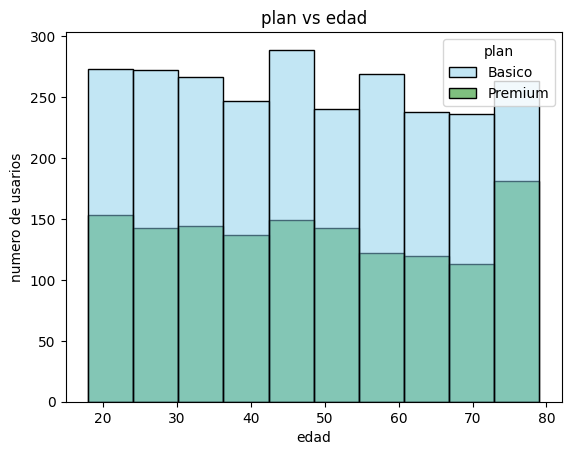

In [26]:


# Histograma para visualizar la edad (age)


sns.histplot(data = user_profile, x = "age",bins=10,hue = 'plan', palette = ["skyblue",'green'])
plt.xlabel("edad")
plt.ylabel("numero de usarios")
plt.title("plan vs edad")
plt.show()





💡Insights: 
- el plan mas contratado es el basico
- la mayor contratacion de plan premium radica en las edades de 20 a 50 años de edad
- la mayor contratacion de plan basico esta entre los 40 y 50 años
- el mayor pico de contratacion premium se encuentra entre los 70 y 80 años

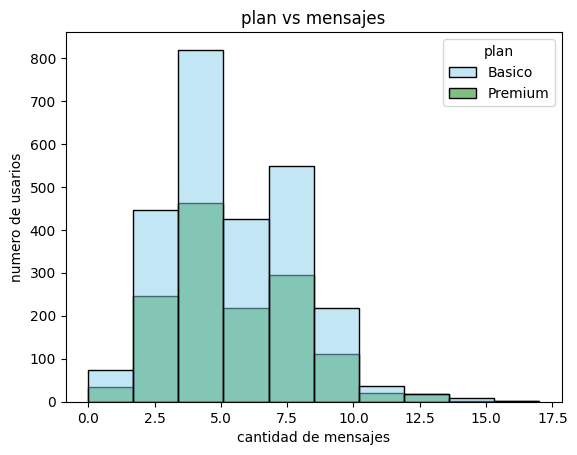

In [27]:
# Histograma para visualizar la cant_mensajes
sns.histplot(data = user_profile, x = "cant_mensajes",bins=10,hue = 'plan', palette = ["skyblue",'green'])
plt.xlabel("cantidad de mensajes")
plt.ylabel("numero de usarios")
plt.title("plan vs mensajes")
plt.show()



💡Insights: 
- La mayor cantidad de mensajes se manda atraves del plan basico
- se observa un pequeño sesgo a la derecha
- El mayor uso de mensajeria para ambos planes se encuentra en 2.5 y 8 mensajes 

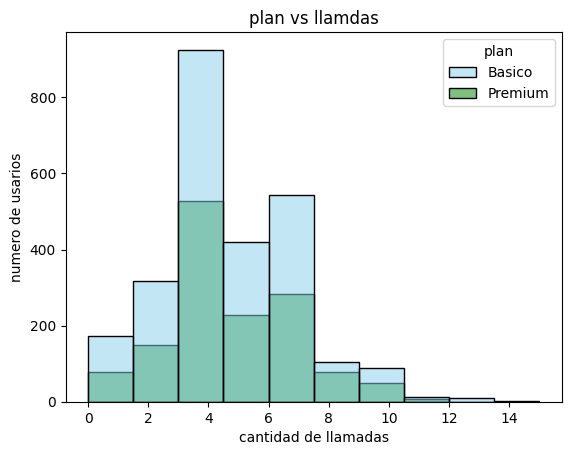

In [28]:
# Histograma para visualizar la cant_llamadas
sns.histplot(data = user_profile, x = "cant_llamadas",bins=10,hue = 'plan', palette = ["skyblue",'green'])
plt.xlabel("cantidad de llamadas")
plt.ylabel("numero de usarios")
plt.title("plan vs llamdas")
plt.show()



💡Insights: 
- Predomina el plan basico en canitdad de llamadas
- Pequeño sesgo a la derecha
- agrupacion de datos ente 0 y 8 llamdas 

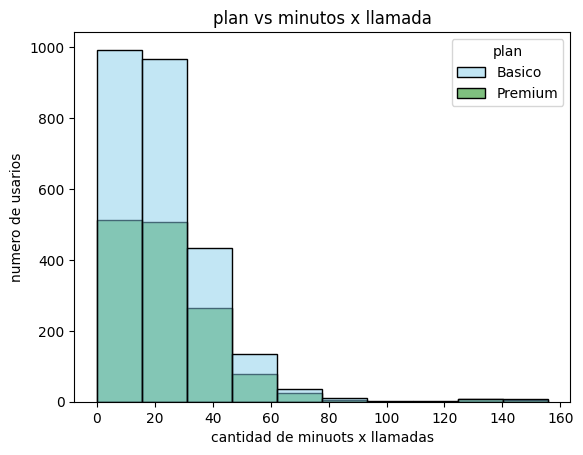

In [29]:
# Histograma para visualizar la cant_minutos_llamada
sns.histplot(data = user_profile, x = "cant_minutos_llamada",bins=10,hue = 'plan', palette = ["skyblue",'green'])
plt.xlabel("cantidad de minuots x llamadas")
plt.ylabel("numero de usarios")
plt.title("plan vs minutos x llamada")
plt.show()


💡Insights: 
- Se observa un sesgo a la derecha
- La mayor concentracion de minutos por llamada se encuentra entre 0 y 40 minutos
  

### 5.2 Identificación de Outliers

🎯 **Objetivo:**  
Detectar valores extremos en las variables clave de **uso** y **clientes** que podrían afectar el análisis, y decidir si requieren limpieza o revisión adicional.

**Instrucciones:**  
- Usa **boxplots** para identificar visualmente outliers en las siguientes columnas:  
  - `age` 
  - `cant_mensajes`
  - `cant_llamadas`
  - `total_minutos_llamada`  
- Crea un **for** para generar los 4 boxplots automáticamente.
<br>

- Después de crear los gráfico, responde si **existen o no outliers** en las variables.  
- Si hay outliers, crea otro bucle para calcular los límites de esas columnas usando el **método IQR** y decide qué hacer con ellos.
  - Si solamente hay outliers de un solo lado, no es necesario calcular ambos límites.

**Hint:**
- Dentro del bucle, usa `plt.title(f'Boxplot: {col}')` para que el título cambie acorde a la columna.

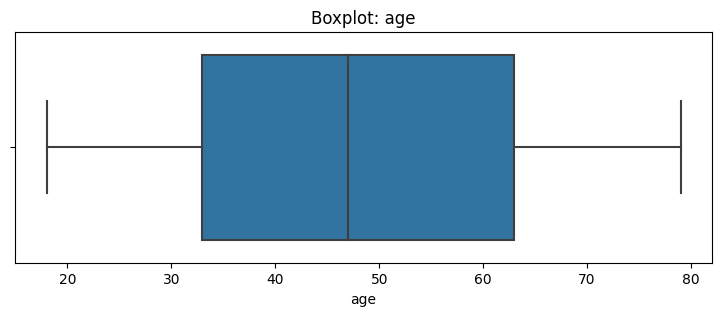

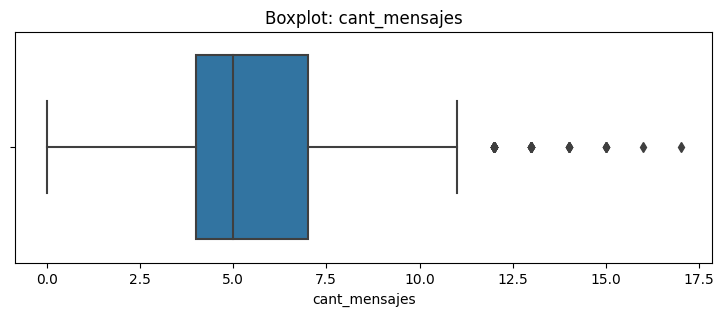

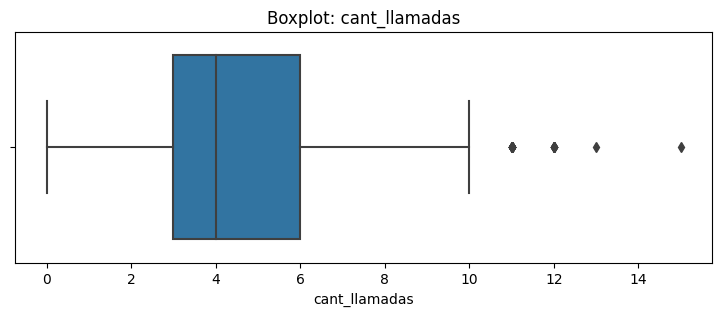

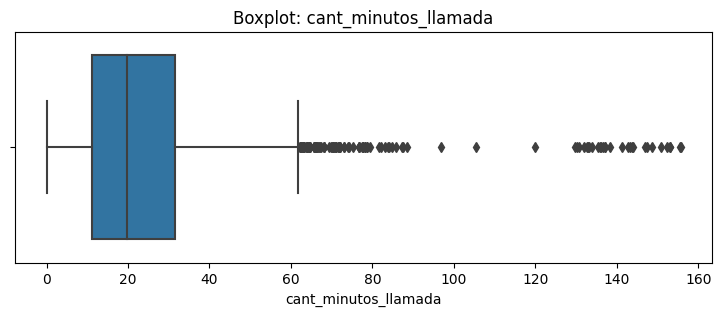

In [31]:
# Visualizando usando BoxPlot 
columnas_numericas = ['age', 'cant_mensajes', 'cant_llamadas', 'cant_minutos_llamada']

for col in columnas_numericas:
    plt.figure(figsize=(9,3))
    sns.boxplot(x=user_profile[col])
    plt.title(f'Boxplot: {col}')
    plt.show()

💡Insights: 
- Age: la columna age no presenta outliers
- cant_mensajes: Tenemos pocos outliers hacua la derecha
- cant_llamadas: presenta pocos outliers hacia la derecha
- cant_minutos_llamada: Presenta muchos outliers hacia la derecha

In [46]:
# Calcular límites con el método IQR
columnas_limites = ['cant_mensajes','cant_llamadas','cant_minutos_llamada']

for col in columnas_limites:
    Q1 = user_profile[col].quantile(0.25)
    Q3 = user_profile[col].quantile(0.75)
    IQR = Q3 - Q1

    print (col,"IQR: ",IQR)

    upper = Q3 + 1.5*IQR
    display(user_profile[(user_profile[col] > upper)])

cant_mensajes IQR:  3.0


,user_id,cant_mensajes,cant_llamadas,cant_minutos_llamada,first_name,last_name,age,city,reg_date,plan,churn_date,year_users
315,10315,13,3,12.36,Carlos,Lopez,30.0,MTY,2022-03-28 06:04:03.060765192,Basico,NaN,2022
347,10347,13,3,21.40,Carlos,Garcia,77.0,Cali,2022-04-06 00:21:36.324081021,Basico,NaN,2022
356,10356,12,5,59.48,Mateo,Garcia,42.0,CDMX,2022-04-08 11:30:17.554388598,Basico,NaN,2022
384,10384,12,3,13.05,Sofia,Ramirez,35.0,CDMX,2022-04-16 03:30:39.159789948,Premium,NaN,2022
456,10456,12,1,2.24,Mateo,Ramirez,47.0,CDMX,2022-05-05 20:40:09.002250564,Basico,"1,72653E+18",2022
539,10539,14,5,8.66,Sofia,Ramirez,77.0,Cali,2022-05-28 14:06:55.903975994,Basico,NaN,2022
591,10591,12,2,16.52,Ana,Gomez,25.0,NaN,2022-06-11 19:50:27.456864216,Basico,NaN,2022
670,10670,12,3,19.13,Carlos,Torres,47.0,Bogotá,2022-07-03 11:00:02.700675170,Basico,NaN,2022
903,10903,12,3,8.89,Carlos,Lopez,63.0,CDMX,2022-09-05 06:11:36.774193548,Premium,"1,72938E+18",2022
908,10908,14,3,12.50,Mariana,Lopez,56.0,MTY,2022-09-06 15:03:06.346586648,Basico,NaN,2022


cant_llamadas IQR:  3.0


,user_id,cant_mensajes,cant_llamadas,cant_minutos_llamada,first_name,last_name,age,city,reg_date,plan,churn_date,year_users
116,10116,3,11,44.32,Ana,Garcia,52.0,CDMX,2022-02-01 18:18:38.079519880,Basico,NaN,2022
417,10417,4,12,26.42,Luis,Garcia,70.0,Bogotá,2022-04-25 04:22:30.337584396,Basico,NaN,2022
777,10777,4,12,55.28,Sofia,Lopez,65.0,Cali,2022-08-01 18:09:59.549887472,Basico,NaN,2022
778,10778,8,11,32.13,Mateo,Lopez,77.0,NaN,2022-08-02 00:44:17.464366092,Basico,NaN,2022
862,10862,4,15,78.11,Luis,Ramirez,23.0,Bogotá,2022-08-25 00:45:22.280570144,Basico,NaN,2022
1013,11013,4,11,60.83,Mateo,Lopez,65.0,CDMX,2022-10-05 09:04:27.366841712,Basico,NaN,2022
1563,11564,8,11,30.17,Carlos,Lopez,41.0,CDMX,2023-03-05 06:02:58.244561144,Basico,NaN,2023
1613,11614,5,11,41.80,Mateo,Garcia,73.0,Bogotá,2023-03-18 22:37:53.968492128,Basico,NaN,2023
1911,11912,2,11,65.71,Mariana,Garcia,48.0,Medellín,2023-06-08 12:58:52.483120784,Premium,NaN,2023
2012,12013,2,12,65.55,Mateo,Lopez,48.0,GDL,2023-07-06 04:43:01.845461368,Basico,NaN,2023


cant_minutos_llamada IQR:  20.295


,user_id,cant_mensajes,cant_llamadas,cant_minutos_llamada,first_name,last_name,age,city,reg_date,plan,churn_date,year_users
27,10027,8,7,84.77,Ana,Gomez,28.0,MTY,2022-01-08 09:26:03.690922730,Premium,NaN,2022
85,10085,6,5,152.36,Carlos,Ramirez,65.0,GDL,2022-01-24 06:35:22.730682670,Basico,NaN,2022
93,10093,2,7,71.57,Ana,Torres,67.0,Medellín,2022-01-26 11:09:46.046511628,Basico,NaN,2022
189,10189,9,4,155.42,Mariana,Torres,63.0,MTY,2022-02-21 18:02:25.836459115,Basico,NaN,2022
198,10198,8,9,78.77,Sofia,Gomez,58.0,Medellín,2022-02-24 05:11:07.066766692,Basico,"1,73033E+18",2022
...,...,...,...,...,...,...,...,...,...,...,...,...
3919,13920,4,5,132.72,Mariana,Lopez,48.0,Bogotá,2024-12-09 08:50:24.756189056,Premium,NaN,2024
3926,13927,8,4,135.96,Mariana,Lopez,18.0,GDL,2024-12-11 06:50:30.157539392,Basico,"1,72549E+18",2024
3944,13945,7,3,133.97,Luis,Ramirez,30.0,Bogotá,2024-12-16 05:07:52.618154544,Basico,NaN,2024
3952,13953,0,7,155.69,Mateo,Gomez,58.0,GDL,2024-12-18 09:42:15.933983504,Basico,NaN,2024


In [45]:
# Revisa los limites superiores y el max, para tomar la decisión de mantener los outliers o no
user_profile[columnas_limites].describe()

,cant_mensajes,cant_llamadas,cant_minutos_llamada
count,3999.000000,3999.000000,3999.000000
mean,5.524381,4.478120,23.317054
std,2.358416,2.144238,18.168095
min,0.000000,0.000000,0.000000
25%,4.000000,3.000000,11.120000
50%,5.000000,4.000000,19.780000
75%,7.000000,6.000000,31.415000
max,17.000000,15.000000,155.690000


💡Insights: 
- cant_mensajes: El valor upper es de 11.5 y el valor maximo es de 17 por lo que estamos dento del rango permitido, en el boxplot se observan pocas cantidades registradas con outliers, tratamiento keep 
- cant_llamadas: El valo upper es de 10.5 y el valor maximo es de 15, estamos dentro del rango permitido, pocas cantidades registradas en boxplot, tratamiendo keep
- cant_minutos_llamada: Vemos que hay outliers fuera del limite, por lo que se va winzorizar

In [52]:

p99 = user_profile['cant_minutos_llamada'].quantile(0.99)
user_profile["cant_minutos_llamada_capped"] = np.clip(user_profile['cant_minutos_llamada'], None, p99)
user_profile["cant_minutos_llamada_capped"].describe()



count    3999.000000
mean       22.864377
std        15.822755
min         0.000000
25%        11.120000
50%        19.780000
75%        31.415000
max        82.197600
Name: cant_minutos_llamada_capped, dtype: float64

---

## 🧩Paso 6: Segmentación de Clientes

### 6.1 Segmentación de Clientes Por Uso

🎯 **Objetivo:** Clasificar a cada usuario en un grupo de uso (Bajo uso, Uso medio, Alto uso) basándose en la cantidad de llamadas y mensajes registrados.

**Instrucciones:**  
- Crea una nueva columna llamada `grupo_uso` en el dataframe `user_profile`.
- Usa comparaciones lógicas (<, >) para evaluar las condiciones de llamadas y mensajes y asigna:
  - `'Bajo uso'` cuando llamadas < 5 y mensajes < 5
  - `'Uso medio'` cuando llamadas < 10 y mensajes < 10
  - `'Alto uso'` para el resto de casos

In [58]:
# Crear columna grupo_uso

def clasificacion_uso(row):
    mensaje = row['cant_mensajes']
    llamada = row['cant_llamadas']

# manejo de valores nulos/faltantes
    if pd.isna(llamada) or pd.isna(mensaje):
        return "Error en Datos"
# sementacion        
    if llamada < 5 and mensaje < 5:
        return "Bajo uso"
    elif llamada < 10 and mensaje < 10:
        return "Uso medio"
    else: 
        return "Alto uso"

user_profile['grupo_uso'] = user_profile.apply(clasificacion_uso,axis=1)
user_profile[['cant_mensajes','cant_llamadas','grupo_uso']].head()

,cant_mensajes,cant_llamadas,grupo_uso
0,7,3,Uso medio
1,5,10,Alto uso
2,5,2,Uso medio
3,11,3,Alto uso
4,4,3,Bajo uso


In [59]:
# verificar cambios
user_profile.head()

,user_id,cant_mensajes,cant_llamadas,cant_minutos_llamada,first_name,last_name,age,city,reg_date,plan,churn_date,year_users,cant_minutos_llamada_capped,grupo_uso
0,10000,7,3,23.70,Carlos,Garcia,38.0,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN,2022,23.70,Uso medio
1,10001,5,10,33.18,Mateo,Torres,53.0,?,2022-01-01 06:34:17.914478619,Basico,NaN,2022,33.18,Alto uso
2,10002,5,2,10.74,Sofia,Ramirez,57.0,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN,2022,10.74,Uso medio
3,10003,11,3,8.99,Mateo,Ramirez,69.0,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN,2022,8.99,Alto uso
4,10004,4,3,8.01,Mateo,Torres,63.0,GDL,2022-01-02 02:17:11.657914478,Basico,NaN,2022,8.01,Bajo uso


### 6.2 Segmentación de Clientes Por Edad

🎯 **Objetivo:**: Clasificar a cada usuario en un grupo por **edad**.

**Instrucciones:**  
- Crea una nueva columna llamada `grupo_edad` en el dataframe `user_profile`.
- Usa comparaciones lógicas (<, >) para evaluar las condiciones y asigna:
  - `'Joven'` cuando age < 30
  - `'Adulto'` cuando age < 60
  - `'Adulto Mayor'` para el resto de casos

In [61]:
user_profile.head(3)

,user_id,cant_mensajes,cant_llamadas,cant_minutos_llamada,first_name,last_name,age,city,reg_date,plan,churn_date,year_users,cant_minutos_llamada_capped,grupo_uso
0,10000,7,3,23.70,Carlos,Garcia,38.0,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN,2022,23.70,Uso medio
1,10001,5,10,33.18,Mateo,Torres,53.0,?,2022-01-01 06:34:17.914478619,Basico,NaN,2022,33.18,Alto uso
2,10002,5,2,10.74,Sofia,Ramirez,57.0,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN,2022,10.74,Uso medio


In [64]:
# Crear columna grupo_edad
def clasificacion_edad(row):
    edad = row['age']
    
# manejod de valores nulos/faltantes
    if pd.isna(edad):
        return "Error en Datos"
# segmentacion de edades        
    if edad < 30:
        return "Joven"
    elif edad < 60:
        return "Adulto"
    else: 
        return "Adulto Mayor"

user_profile['grupo_edad'] = user_profile.apply(clasificacion_edad,axis=1)
user_profile[['age','grupo_edad']].head()

,age,grupo_edad
0,38.0,Adulto
1,53.0,Adulto
2,57.0,Adulto
3,69.0,Adulto Mayor
4,63.0,Adulto Mayor


In [65]:
# verificar cambios
user_profile.head()

,user_id,cant_mensajes,cant_llamadas,cant_minutos_llamada,first_name,last_name,age,city,reg_date,plan,churn_date,year_users,cant_minutos_llamada_capped,grupo_uso,grupo_edad
0,10000,7,3,23.70,Carlos,Garcia,38.0,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN,2022,23.70,Uso medio,Adulto
1,10001,5,10,33.18,Mateo,Torres,53.0,?,2022-01-01 06:34:17.914478619,Basico,NaN,2022,33.18,Alto uso,Adulto
2,10002,5,2,10.74,Sofia,Ramirez,57.0,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN,2022,10.74,Uso medio,Adulto
3,10003,11,3,8.99,Mateo,Ramirez,69.0,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN,2022,8.99,Alto uso,Adulto Mayor
4,10004,4,3,8.01,Mateo,Torres,63.0,GDL,2022-01-02 02:17:11.657914478,Basico,NaN,2022,8.01,Bajo uso,Adulto Mayor


### 6.3 Visualización de la Segmentación de Clientes

🎯 **Objetivo:** Visualizar la distribución de los usuarios según los grupos creados: **grupo_uso** y **grupo_edad**.

**Instrucciones:**  
- Crea dos gráficos para las variables categóricas `grupo_uso` y `grupo_edad`.
- Agrega título y etiquetas a los ejes en cada gráfico.

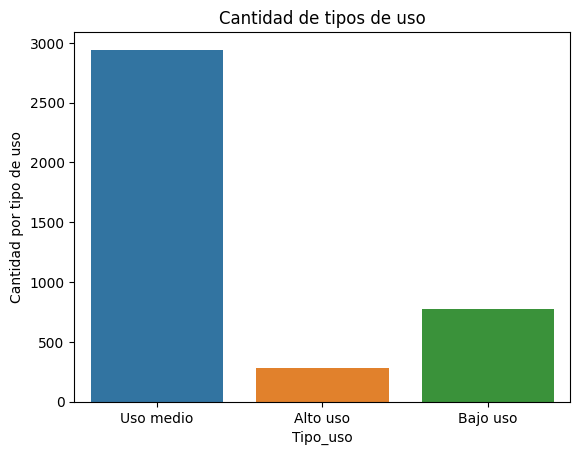

In [67]:
# Visualización de los segmentos por uso
sns.countplot(data = user_profile, x='grupo_uso')
plt.xlabel("Tipo_uso")
plt.ylabel("Cantidad por tipo de uso")
plt.title("Cantidad de tipos de uso")
plt.show()

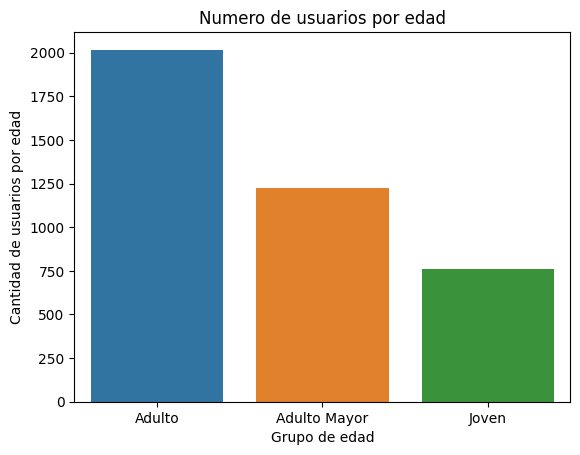

In [68]:
# Visualización de los segmentos por edad
sns.countplot(data = user_profile, x='grupo_edad')
plt.xlabel("Grupo de edad")
plt.ylabel("Cantidad de usuarios por edad")
plt.title("Numero de usuarios por edad")
plt.show()



---
## 🧩Paso 7: Insight Ejecutivo para Stakeholders

🎯 **Objetivo:** Traducir los hallazgos del análisis en conclusiones accionables para el negocio, enfocadas en segmentación, patrones de uso y oportunidades comerciales.

**Preguntas a responder:** 
- ¿Qué problemas tenían originalmemte los datos?¿Qué porcentaje, o cantidad de filas, de esa columna representaban?

- Los datos tenian valores nullos y precensia de outliers, las columnas con mayor numero de nullos fue la columna "city" en el dataset "users" estos nullos reflejaban un 11 % de todos los registros 
- Precensia de outliers en la columna duration

  
- ¿Qué segmentos de clientes identificaste y cómo se comportan según su edad y nivel de uso?

- Segmentacion por tipos de uso, observamos que la mayor parte de los usarios realiza entre 0 y 10 intereacciones entre llamadas y mensajes, seguido de interaccion menor entre 0 y 5 llamdas y mensajes
- La mayor interaccion en los planes se observa en las personas adultas 

- ¿Qué segmentos parecen más valiosos para ConnectaTel y por qué?

- El segmento mas valioso son las personas adultas que tienen una interaccion media atraves de llamadas y mensajes, este resultado se obtiene del estudio entre cantidad de interacciones por grupo de edades
  
- ¿Qué patrones de uso extremo (outliers) encontraste y qué implican para el negocio?

- Los outliers se encontrarn en la duracion de las llamadas y esto puede implicar un ajuste en la cantidad de miutos vendido o manejados en cada llamada o mensaje

- ¿Qué recomendaciones harías para mejorar la oferta actual de planes o crear nuevos planes basados en los segmentos y patrones detectados?

Es correcto hacer el mismo analisis de agrupacion de tipos de uso para cada plan contratado y poder evaluar los beneficios ofrecidos por cada uno de los planes, con esto tratar que el usuario tenga un mayor numero de interacciones para poder vender mas planes 

✍️ **Escribe aquí tu análisis ejecutivo:**

### Análisis ejecutivo

⚠️ **Problemas detectados en los datos**

- Los datos tenian valores nullos y precensia de outliers, las columnas con mayor numero de nullos fue la columna "city" en el dataset "users" estos nullos reflejaban un 11 % de todos los registros 
- Precensia de outliers en la columna duration


🔍 **Segmentos por Edad**

- Las personas adultas son las que ocupar mayormente el servicio, represnetando la mitad de la miestra total. 
- las personas con menor uso del servicio son las personas adultas mayores 


📊 **Segmentos por Nivel de Uso**

- la mayoria de los casos se concentran en un uso medio por lo que el sesgo de consumo es moderado
- una quinta parte es de bajo uso por lo que puede representar un foco de abandono


➡️ Esto sugiere que ...

- El bajo consumo de interacciones puede corresponde al segmento de adultos mayores
- El mayor uso puede estar presente en el rango de edades que tienen persiven un flujo de efectivo

💡 **Recomendaciones**

- Podemos diseñar planes o mudulos que insentivan un mayor uso de los beneficios para cada plan
- Crear planes para jovenes que sean mas accesibles
- Podemos hacer pruebas de cruze de informacion para ver la dependencia que existe entre ambos segmentos
  

---

## 🧩Paso 8 Cargar tu notebook y README a GitHub

🎯 **Objetivo:**  
Entregar tu análisis de forma **profesional**, **documentada** y **versionada**, asegurando que cualquier persona pueda revisar, ejecutar y entender tu trabajo.



### Opción A : Subir archivos desde la interfaz de GitHub (UI)

1. Descarga este notebook (`File → Download .ipynb`).  
2. Entra a tu repositorio en GitHub (por ejemplo `telecom-analysis` o `sprint7-final-project`).  
3. Sube tu notebook **Add file → Upload files**.  

---

### Opción B : Guardar directo desde Google Colab

1. Abre tu notebook en Colab.  
2. Ve a **File → Save a copy in GitHub**.  
3. Selecciona el repositorio y la carpeta correcta (ej: `notebooks/`).  
4. Escribe un mensaje de commit claro, por ejemplo:  
    - `feat: add final ConnectaTel analysis`
    - `agregar version final: Análisis ConnectaTel`
5. Verifica en GitHub que el archivo quedó en el lugar correcto y que el historial de commits se mantenga limpio.

---

Agrega un archivo `README.md` que describa de forma clara:
- el objetivo del proyecto,  
- los datasets utilizados,  
- las etapas del análisis realizadas,  
- cómo ejecutar el notebook (por ejemplo, abrirlo en Google Colab),  
- una breve guía de reproducción.
---

Link a repositorio público del proyecto: `LINK a tu repo aquí`